# Split criteria on DICES (informal test)

One tree skeleton, ten interchangeable split scores (the five PEG formulations plus five others), run on the real data: DICES-350 and
DICES-990. Nothing in `polartox/` or `modules/` is changed.

The hyperparameters are **fixed**: the shared tree settings and each criterion's own threshold come from the earlier tuning on the
synthetic corpora A to J (best mean Jaccard of the planted dimensions) and are written into section 1. **The synthetic corpora are not
used or evaluated in this notebook.** Everything below is measured on DICES only, at those thresholds, with **no tree-size matching**.

| Criterion | What it scores |
|---|---|
| **PEG harmonic** | harmonic mean of the max, weighted and min comparisons of nDFU (as in `polartox`) |
| **PEG weighted** | `|nDFU(node) - sum_g w_g nDFU(g)|` |
| **PEG max / min / mean** | the same comparison against the most polarised subgroup (max), the least polarised one (min), or the arithmetic mean of max, weighted and min |
| **Variance reduction** | `Var(node) - sum_g w_g Var(g)` |
| **JSD** | size-weighted generalised Jensen-Shannon divergence between the subgroups; with size weights this equals the entropy information gain |
| **Wasserstein** | `sum_g w_g W1(subgroup g, node)` on the ordered scale |
| **Gain ratio (C4.5)** | information gain divided by the split information |
| **KL from node** | `sum_g w_g KL(subgroup g || node)` with add-one smoothing |

Sections: 1 setup, 2 criteria, 3 residual nDFU, 4 behavioural comparison, 5 Wilcoxon tests, 6 explanation efficiency, 7 save.

## 1. Setup, fixed hyperparameters and imports

In [1]:
import os, sys, time, itertools
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except Exception as err:                       # the heatmap of section 4 is optional: the tables and the csv files do not need it
    plt = None
    print("matplotlib is not available, the figure of section 4 is skipped:", str(err)[:120])
from ndfu import dfu
from sklearn.metrics import adjusted_rand_score

from polartox.polarized_tree import jaccard


def find_root():
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "polartox").is_dir() and (p / "modules").is_dir():
            return p
    raise FileNotFoundError("Run this notebook from inside the repository.")


ROOT = find_root()

# ---- fixed hyperparameters: the selected configuration of the synthetic search, shared by every criterion
SHARED = dict(theta_filter=0.30, min_size_frac=0.02, max_depth=4, theta_stop=0.10)

# ---- each criterion's own threshold (relative = gain divided by the node's own spread), tuned earlier on the synthetic corpora A to J
best = {
    "PEG harmonic":         dict(relative=True,  h=0.20),
    "PEG weighted":         dict(relative=True,  h=0.15),
    "PEG max":              dict(relative=False, h=0.20),
    "PEG min":              dict(relative=True,  h=0.40),
    "PEG mean":             dict(relative=True,  h=0.40),
    "Variance reduction":   dict(relative=True,  h=0.05),
    "JSD (= entropy gain)": dict(relative=False, h=0.02),
    "Wasserstein":          dict(relative=True,  h=0.30),
    "Gain ratio (C4.5)":    dict(relative=False, h=0.02),
    "KL from node":         dict(relative=False, h=0.02),
}
SCALE, DIMS = 3, ["gender", "race", "age", "education"]          # DICES: three rating levels, four dimensions
print("repo root:", ROOT)
print("shared:", SHARED)


def prep_text(df, dims):
    y = df["rating"].to_numpy().astype(np.int64)
    codes = {d: pd.factorize(df[d], sort=True)[0].astype(np.int64) for d in dims}
    return dict(y=y, codes=codes, levels={d: int(codes[d].max()) + 1 for d in dims})


@lru_cache(maxsize=None)
def _ndfu_counts(counts):
    n = sum(counts)
    return float("nan") if n == 0 else float(dfu(np.array(counts, dtype=float) / n))


def ndfu_c(counts):
    return _ndfu_counts(tuple(int(c) for c in counts))

repo root: C:\Users\Sokratis\OneDrive\Υπολογιστής\ερευνα\HumanModelAlign\polarizedtrees
shared: {'theta_filter': 0.3, 'min_size_frac': 0.02, 'max_depth': 4, 'theta_stop': 0.1}


## 2. The criteria

Every criterion has the same signature: `score(node, groups)` where `node` is the rating histogram of the node and `groups` the rating
histograms of the subgroups a split would create (the node's annotators summarised by rating, which is all a score needs). It returns
`(gain, node_spread)`: the gain of the split and the node's own disagreement on the same scale, which the *relative* threshold divides by
(the analogue of `relative_h`). All gains are scaled to about 0..1.

In [2]:
R = np.arange(1, SCALE + 1)


def _entropy(c):
    p = c / c.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def _var(c, r):
    n = c.sum()
    m = (c * r).sum() / n
    return float((c * (r - m) ** 2).sum() / n)


def score_peg(node, groups, variant):
    g = ndfu_c(node)
    nds = [ndfu_c(c) for c in groups]
    n = node.sum()
    peg_max = abs(g - max(nds))
    peg_w = abs(g - sum(c.sum() / n * x for c, x in zip(groups, nds)))
    peg_min = abs(g - min(nds))
    if variant == "weighted":
        return peg_w, g
    if variant == "max":                                               # the most polarised subgroup
        return peg_max, g
    if variant == "min":                                               # the least polarised subgroup
        return peg_min, g
    if variant == "mean":                                              # arithmetic mean of max, weighted and min
        return (peg_max + peg_w + peg_min) / 3, g
    if peg_max > 0 and peg_w > 0 and peg_min > 0:                      # harmonic mean, beta = 1 (as in polartox)
        return 3.0 / (1 / peg_max + 1 / peg_w + 1 / peg_min), g
    return 0.0, g


def score_peg_harmonic(node, groups):
    return score_peg(node, groups, "harmonic")


def score_peg_weighted(node, groups):
    return score_peg(node, groups, "weighted")


def score_peg_max(node, groups):
    return score_peg(node, groups, "max")


def score_peg_min(node, groups):
    return score_peg(node, groups, "min")


def score_peg_mean(node, groups):
    return score_peg(node, groups, "mean")


def score_variance_reduction(node, groups):
    r = np.arange(1, len(node) + 1)
    top = (len(node) - 1) ** 2 / 4                                   # the largest possible variance
    n = node.sum()
    within = sum(c.sum() / n * _var(c, r) for c in groups)
    v = _var(node, r)
    return (v - within) / top, v / top


def score_jsd(node, groups):
    """size-weighted generalised Jensen-Shannon divergence = H(node) - sum w_g H(g), in bits, scaled by log2(scale)."""
    n = node.sum()
    top = np.log2(len(node))
    h = _entropy(node)
    return (h - sum(c.sum() / n * _entropy(c) for c in groups)) / top, h / top


def score_wasserstein(node, groups):
    """sum_g w_g W1(subgroup g, node) on the ordered scale (W1 = sum of |CDF difference|), scaled by scale-1."""
    k = len(node)
    n = node.sum()
    cdf = np.cumsum(node / n)
    gain = sum(c.sum() / n * np.abs(np.cumsum(c / c.sum()) - cdf)[:-1].sum() for c in groups) / (k - 1)
    med = int(np.searchsorted(cdf, 0.5)) + 1                          # the node's own spread: mean distance to its median
    spread = float(((node / n) * np.abs(np.arange(1, k + 1) - med)).sum() / (k - 1))
    return gain, spread


def score_gain_ratio(node, groups):
    """C4.5 gain ratio = information gain / split information (the entropy of how the split divides the annotators).
    The information gain is divided by log2(scale) so it is on a 0..1 scale like the other scores: a constant factor, which
    cannot change which dimension wins at a node, it only rescales the threshold."""
    k = len(node)
    n = node.sum()
    w = np.array([c.sum() for c in groups], float) / n
    top = np.log2(k)
    h = _entropy(node)
    info_gain = h - sum(wi * _entropy(c) for wi, c in zip(w, groups))
    split_info = float(-(w * np.log2(w)).sum())
    if split_info <= 0:
        return 0.0, h / top
    return (info_gain / top) / split_info, h / top


def score_kl_from_node(node, groups):
    """size-weighted mean of KL(subgroup || node), add-one smoothed so that nothing is log(0); in bits, scaled by log2(scale).
    Without smoothing this is exactly the information gain (the same quantity as the size-weighted JSD above)."""
    k = len(node)
    n = node.sum()
    top = np.log2(k)
    p_node = (node + 1) / (n + k)
    total = 0.0
    for c in groups:
        p = (c + 1) / (c.sum() + k)
        total += c.sum() / n * float((p * np.log2(p / p_node)).sum())
    return total / top, _entropy(node) / top


CRITERIA = {
    "PEG harmonic": score_peg_harmonic,
    "PEG weighted": score_peg_weighted,
    "PEG max": score_peg_max,
    "PEG min": score_peg_min,
    "PEG mean": score_peg_mean,
    "Variance reduction": score_variance_reduction,
    "JSD (= entropy gain)": score_jsd,
    "Wasserstein": score_wasserstein,
    "Gain ratio (C4.5)": score_gain_ratio,
    "KL from node": score_kl_from_node,
}

# the tiny check: on a polarised node, split into its two camps, every score is clearly positive; on a split of identical groups, ~0
node = np.array([50, 0, 0, 0, 50]); camps = [np.array([50, 0, 0, 0, 0]), np.array([0, 0, 0, 0, 50])]; same = [np.array([25, 0, 0, 0, 25])] * 2
for k, f in CRITERIA.items():
    print(f"{k:22s} polarised split: gain {f(node, camps)[0]:.3f} (node spread {f(node, camps)[1]:.3f})   identical groups: gain {f(node, same)[0]:.3f}")

PEG harmonic           polarised split: gain 1.000 (node spread 1.000)   identical groups: gain 0.000
PEG weighted           polarised split: gain 1.000 (node spread 1.000)   identical groups: gain 0.000
PEG max                polarised split: gain 1.000 (node spread 1.000)   identical groups: gain 0.000
PEG min                polarised split: gain 1.000 (node spread 1.000)   identical groups: gain 0.000
PEG mean               polarised split: gain 1.000 (node spread 1.000)   identical groups: gain 0.000
Variance reduction     polarised split: gain 1.000 (node spread 1.000)   identical groups: gain 0.000
JSD (= entropy gain)   polarised split: gain 0.431 (node spread 0.431)   identical groups: gain 0.000
Wasserstein            polarised split: gain 0.500 (node spread 0.500)   identical groups: gain 0.000
Gain ratio (C4.5)      polarised split: gain 0.431 (node spread 0.431)   identical groups: gain 0.000
KL from node           polarised split: gain 0.357 (node spread 0.431)   identical

### The skeleton

The same greedy tree as `polartox.polarized_tree.detect_polarized_subgroups` (same stop rules, same use of `min_size`, strict `>` for the
best score, same relative comparison), with the score as a parameter.

In [3]:
def build_tree(T, crit, h, relative, shared=SHARED, scale=SCALE, dims=DIMS, labels=False):
    y, codes, levels = T["y"], T["codes"], T["levels"]
    n_total = len(y)
    min_size = max(2, round(shared["min_size_frac"] * n_total))
    leaves, used, decisions = [], set(), {}
    lab = np.zeros(n_total, dtype=np.int64) if labels else None

    def leaf(idx, nd, path):
        decisions[path] = None
        if labels:
            lab[idx] = len(leaves)
        leaves.append((len(idx), nd))

    def dfs(idx, remaining, depth, path):
        yy = y[idx]
        counts = np.bincount(yy - 1, minlength=scale)
        nd = ndfu_c(counts)
        if nd < shared["theta_stop"] or depth > shared["max_depth"] or not remaining:
            return leaf(idx, nd, path)
        best_dim, best_gain, best_spread = None, 0.0, 0.0
        for d in remaining:
            cd = codes[d][idx]
            ok = cd >= 0
            k = levels[d]
            hist = np.bincount(cd[ok] * scale + yy[ok] - 1, minlength=k * scale).reshape(k, scale)
            sizes = hist.sum(axis=1)
            keep = np.flatnonzero(sizes)
            if (sizes[keep] < min_size).any():
                continue
            gain, spread = crit(counts, [hist[g] for g in keep])
            if gain > best_gain:
                best_dim, best_gain, best_spread = d, gain, spread
        value = (best_gain / best_spread if best_spread > 0 else 0.0) if relative else best_gain
        if best_dim is None or value <= h:
            return leaf(idx, nd, path)
        used.add(best_dim)
        decisions[path] = best_dim
        cd = codes[best_dim][idx]
        rest = [d for d in remaining if d != best_dim]
        for g in np.unique(cd[cd >= 0]):
            dfs(idx[cd == g], rest, depth + 1, path + ((best_dim, int(g)),))

    dfs(np.arange(n_total), list(dims), 1, ())
    return dict(found=used, leaves=leaves, labels=lab, decisions=decisions, first=decisions.get(()))

## 3. Residual nDFU on DICES at each criterion's own tuned threshold (no tree-size matching)

Same preprocessing as `Dices/DICES_polarized_trees_end_to_end.ipynb` (four dimensions, same excluded and renamed categories,
`No / Unsure / Yes` -> `1 / 2 / 3`, scale 3, same `theta_filter`). The files are read from `datasets/dices_350.csv` and
`datasets/dices_990.csv` (or the folder above, or `DICES_DIR`). The overall bias question is `Q3_bias_overall` in the 350 file and
`Q3_unfair_bias_overall` in the 990 file (the same question, named differently).

Each criterion runs on the DICES items at the threshold fixed in section 1 (tuned earlier on the synthetic corpora), carried over unchanged,
the way the DICES notebook carries over the selected configuration. **Nothing is matched or interpolated:** the trees have whatever size
that threshold gives, so the mean number of leaves per tree is printed next to the residual. A bigger tree leaves less polarization, so
read the two columns together.

In [4]:
SEARCH_DIRS = [Path(os.environ["DICES_DIR"])] if "DICES_DIR" in os.environ else []
SEARCH_DIRS += [ROOT / "datasets", ROOT.parent]


def find_dices(stem):
    for d in SEARCH_DIRS:
        if d.is_dir():
            for p in d.glob("*.csv"):
                if p.name.lower() == f"{stem}.csv":
                    return p
    return None


DICES_FILES = {"DICES-350": find_dices("dices_350"), "DICES-990": find_dices("dices_990")}
METRIC_COLUMN = {"DICES-350": "Q3_bias_overall", "DICES-990": "Q3_unfair_bias_overall"}
RUN_DICES = all(p is not None for p in DICES_FILES.values())
D_SCALE, D_DIMS = 3, ["gender", "race", "age", "education"]
RATING_MAP = {"No": 1, "Unsure": 2, "Yes": 3}
EXCLUDED = {"rater_gender": ["Nonbinary", "Self-describe (below)"], "rater_race": ["Other", "Multiracial"], "rater_education": ["Other"]}
RENAME = {"rater_race": {"Asian/Asian subcontinent": "Asian", "Black/African American": "Black",
                         "LatinX, Latino, Hispanic or Spanish Origin": "Hispanic/Latino"},
          "rater_age": {"gen z": "Gen Z", "millenial": "Millennial", "gen x+": "Gen X+"},
          "rater_education": {"College degree or higher": "Degree+", "High school or below": "High School or Below"}}


def load_dices(path, metric):
    df = pd.read_csv(path, usecols=["item_id", "rater_gender", "rater_race", "rater_age", "rater_education", metric])
    df = df.rename(columns={metric: "Q3_bias_overall"})
    for col, cats in EXCLUDED.items():
        df = df[~df[col].isin(cats)]
    for col, mapping in RENAME.items():
        df[col] = df[col].replace(mapping)
    df["rating"] = df["Q3_bias_overall"].map(RATING_MAP)
    assert df["rating"].notna().all()
    df = df.rename(columns={"item_id": "text_id", "rater_gender": "gender", "rater_race": "race", "rater_age": "age", "rater_education": "education"})
    return df[["text_id", *D_DIMS, "rating"]].reset_index(drop=True)


dices = {}
print("DICES files:", {k: (str(v) if v else None) for k, v in DICES_FILES.items()})
if RUN_DICES:
    for name, path in DICES_FILES.items():
        df = load_dices(path, METRIC_COLUMN[name])
        items = {t: prep_text(g.reset_index(drop=True), D_DIMS) for t, g in df.groupby("text_id")}
        keep = sorted(t for t, T in items.items() if ndfu_c(np.bincount(T["y"] - 1, minlength=D_SCALE)) >= SHARED["theta_filter"])
        dices[name] = dict(items=items, retained=keep)
        print(f"{name}: {len(df):,} annotations, {len(items)} items, {len(keep)} retained")
else:
    print("-> put dices_350.csv and dices_990.csv in datasets/ (or set DICES_DIR) and re-run; the notebook cannot run.")

DICES files: {'DICES-350': 'C:\\Users\\Sokratis\\OneDrive\\Υπολογιστής\\ερευνα\\HumanModelAlign\\polarizedtrees\\datasets\\dices_350.csv', 'DICES-990': 'C:\\Users\\Sokratis\\OneDrive\\Υπολογιστής\\ερευνα\\HumanModelAlign\\polarizedtrees\\datasets\\dices_990.csv'}


DICES-350: 35,350 annotations, 350 items, 28 retained


DICES-990: 45,379 annotations, 990 items, 105 retained


In [5]:
# build the DICES trees once, at each criterion's tuned threshold; the later sections reuse them
dices_trees, dices_table = {}, {}
if RUN_DICES:
    t0 = time.time()
    for name in dices:
        d = dices[name]
        dices_trees[name] = {c: {t: build_tree(d["items"][t], CRITERIA[c], best[c]["h"], best[c]["relative"],
                                               scale=D_SCALE, dims=D_DIMS, labels=True) for t in d["retained"]}
                             for c in CRITERIA}
        rows = {}
        for c in CRITERIA:
            tr = dices_trees[name][c]
            ids = d["retained"]
            rows[c] = dict(
                threshold=("relative " if best[c]["relative"] else "absolute ") + str(best[c]["h"]),
                leaves_per_tree=float(np.mean([len(tr[t]["leaves"]) for t in ids])),
                residual_nDFU_unweighted=float(np.mean([np.mean([nd for _, nd in tr[t]["leaves"]]) for t in ids])),
                residual_nDFU_weighted=float(np.mean([sum(n * nd for n, nd in tr[t]["leaves"]) / sum(n for n, _ in tr[t]["leaves"]) for t in ids])))
        dices_table[name] = pd.DataFrame.from_dict(rows, orient="index")
    print(f"trees built ({time.time() - t0:.0f}s)")

trees built (1s)


In [6]:
if RUN_DICES:
    for name, tab in dices_table.items():
        print(f"{name}: {len(dices[name]['retained'])} polarised items, each criterion at its tuned threshold, no size matching")
        display(tab.sort_values("residual_nDFU_weighted").round(4))
    both = pd.DataFrame({n: t["residual_nDFU_weighted"] for n, t in dices_table.items()})
    both["both (mean)"] = both.mean(axis=1)
    both = both.sort_values("both (mean)")
    both["rank"] = range(1, len(both) + 1)
    print("\nResidual nDFU (annotator-weighted) at each criterion's tuned threshold, no size matching (lower is better)")
    display(both.round(4))
    print("\nMean leaves per tree at the same settings")
    display(pd.DataFrame({n: t["leaves_per_tree"] for n, t in dices_table.items()}).round(2))

DICES-350: 28 polarised items, each criterion at its tuned threshold, no size matching


,threshold,leaves_per_tree,residual_nDFU_unweighted,residual_nDFU_weighted
JSD (= entropy gain),absolute 0.02,15.5357,0.3776,0.3947
PEG min,relative 0.4,13.1786,0.3745,0.4019
KL from node,absolute 0.02,13.2143,0.3985,0.4059
PEG harmonic,relative 0.2,7.5357,0.4158,0.4441
Gain ratio (C4.5),absolute 0.02,10.2500,0.4399,0.4494
PEG weighted,relative 0.15,4.8214,0.4444,0.4603
Variance reduction,relative 0.05,4.8571,0.4749,0.4839
PEG max,absolute 0.2,10.4286,0.4823,0.4985
PEG mean,relative 0.4,6.7857,0.4948,0.5136
Wasserstein,relative 0.3,3.3214,0.5179,0.5270


DICES-990: 105 polarised items, each criterion at its tuned threshold, no size matching


,threshold,leaves_per_tree,residual_nDFU_unweighted,residual_nDFU_weighted
KL from node,absolute 0.02,9.7810,0.3350,0.3431
PEG min,relative 0.4,9.0762,0.3205,0.3465
JSD (= entropy gain),absolute 0.02,9.7238,0.3309,0.3490
Gain ratio (C4.5),absolute 0.02,8.8762,0.3362,0.3708
Variance reduction,relative 0.05,7.0381,0.3512,0.3734
PEG weighted,relative 0.15,4.3238,0.3780,0.3872
PEG mean,relative 0.4,7.7143,0.3718,0.3958
PEG harmonic,relative 0.2,5.2571,0.3881,0.4064
Wasserstein,relative 0.3,4.8857,0.4000,0.4277
PEG max,absolute 0.2,7.2476,0.4592,0.4396



Residual nDFU (annotator-weighted) at each criterion's tuned threshold, no size matching (lower is better)


,DICES-350,DICES-990,both (mean),rank
JSD (= entropy gain),0.3947,0.3490,0.3718,1
PEG min,0.4019,0.3465,0.3742,2
KL from node,0.4059,0.3431,0.3745,3
Gain ratio (C4.5),0.4494,0.3708,0.4101,4
PEG weighted,0.4603,0.3872,0.4237,5
PEG harmonic,0.4441,0.4064,0.4252,6
Variance reduction,0.4839,0.3734,0.4287,7
PEG mean,0.5136,0.3958,0.4547,8
PEG max,0.4985,0.4396,0.4690,9
Wasserstein,0.5270,0.4277,0.4774,10



Mean leaves per tree at the same settings


,DICES-350,DICES-990
PEG harmonic,7.54,5.26
PEG weighted,4.82,4.32
PEG max,10.43,7.25
PEG min,13.18,9.08
PEG mean,6.79,7.71
Variance reduction,4.86,7.04
JSD (= entropy gain),15.54,9.72
Wasserstein,3.32,4.89
Gain ratio (C4.5),10.25,8.88
KL from node,13.21,9.78


## 4. Behavioural comparison

Each criterion at its fixed threshold, on the same DICES items. For every polarised item we compare the trees the criteria build:

- **ARI** of the groupings of the annotators (the leaves), as in Figure 3 of the paper;
- **the first split** (the dimension chosen at the root) and **the node-level agreement**: among the nodes that two trees both reach
  (same path), how often they make the same decision (same dimension, or both stop);
- **the Jaccard of the sets of dimensions** the two trees split on.

Averages are over texts.

In [7]:
def trees_for(texts_by_id, ids, crit_name, scale, dims):
    c = best[crit_name]
    return {t: build_tree(texts_by_id[t], CRITERIA[crit_name], c["h"], c["relative"], scale=scale, dims=dims, labels=True) for t in ids}


def agreement(trees_by_crit):
    names = list(trees_by_crit)
    out = {m: pd.DataFrame(np.eye(len(names)), index=names, columns=names) for m in ("ARI", "first split", "node-level", "dimension sets (Jaccard)")}
    ids = list(next(iter(trees_by_crit.values())))
    for a, b in itertools.combinations(names, 2):
        ari, fs, nl, dj = [], [], [], []
        for t in ids:
            ta, tb = trees_by_crit[a][t], trees_by_crit[b][t]
            ari.append(adjusted_rand_score(ta["labels"], tb["labels"]))
            fs.append(float(ta["first"] == tb["first"]))
            common = set(ta["decisions"]) & set(tb["decisions"])
            nl.append(np.mean([ta["decisions"][p] == tb["decisions"][p] for p in common]))
            dj.append(jaccard(ta["found"], tb["found"]))
        for m, v in (("ARI", ari), ("first split", fs), ("node-level", nl), ("dimension sets (Jaccard)", dj)):
            out[m].loc[a, b] = out[m].loc[b, a] = float(np.mean(v))
    return out


def heatmap(ax, matrix, title):
    im = ax.imshow(matrix.to_numpy(float), vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(matrix))); ax.set_xticklabels(matrix.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(matrix))); ax.set_yticklabels(matrix.index, fontsize=8)
    for i, j in itertools.product(range(len(matrix)), repeat=2):
        v = matrix.to_numpy(float)[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "black")
    ax.set_title(title, fontsize=10)


DICES-350: 28 polarised items
ARI


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.000,0.637,0.256,0.546,0.590,0.747,0.459,0.581,0.421,0.594
PEG weighted,0.637,1.000,0.098,0.374,0.412,0.664,0.294,0.662,0.395,0.427
PEG max,0.256,0.098,1.000,0.399,0.447,0.272,0.439,0.286,0.373,0.326
PEG min,0.546,0.374,0.399,1.000,0.542,0.472,0.622,0.358,0.432,0.704
PEG mean,0.590,0.412,0.447,0.542,1.000,0.685,0.429,0.683,0.573,0.530
Variance reduction,0.747,0.664,0.272,0.472,0.685,1.000,0.410,0.819,0.605,0.530
JSD (= entropy gain),0.459,0.294,0.439,0.622,0.429,0.410,1.000,0.289,0.588,0.697
Wasserstein,0.581,0.662,0.286,0.358,0.683,0.819,0.289,1.000,0.600,0.416
Gain ratio (C4.5),0.421,0.395,0.373,0.432,0.573,0.605,0.588,0.600,1.000,0.583
KL from node,0.594,0.427,0.326,0.704,0.530,0.530,0.697,0.416,0.583,1.000


first split


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.000,0.714,0.286,0.714,0.679,0.786,0.607,0.607,0.429,0.750
PEG weighted,0.714,1.000,0.107,0.500,0.464,0.714,0.393,0.714,0.429,0.536
PEG max,0.286,0.107,1.000,0.500,0.536,0.286,0.500,0.321,0.393,0.429
PEG min,0.714,0.500,0.500,1.000,0.607,0.571,0.714,0.393,0.393,0.786
PEG mean,0.679,0.464,0.536,0.607,1.000,0.750,0.500,0.714,0.571,0.607
Variance reduction,0.786,0.714,0.286,0.571,0.750,1.000,0.500,0.821,0.607,0.643
JSD (= entropy gain),0.607,0.393,0.500,0.714,0.500,0.500,1.000,0.321,0.536,0.821
Wasserstein,0.607,0.714,0.321,0.393,0.714,0.821,0.321,1.000,0.643,0.464
Gain ratio (C4.5),0.429,0.429,0.393,0.393,0.571,0.607,0.536,0.643,1.000,0.607
KL from node,0.750,0.536,0.429,0.786,0.607,0.643,0.821,0.464,0.607,1.000


node-level


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.000,0.670,0.228,0.573,0.614,0.703,0.472,0.559,0.380,0.615
PEG weighted,0.670,1.000,0.088,0.395,0.432,0.636,0.317,0.676,0.398,0.457
PEG max,0.228,0.088,1.000,0.396,0.458,0.215,0.346,0.278,0.289,0.296
PEG min,0.573,0.395,0.396,1.000,0.548,0.492,0.639,0.345,0.351,0.691
PEG mean,0.614,0.432,0.458,0.548,1.000,0.696,0.441,0.664,0.526,0.542
Variance reduction,0.703,0.636,0.215,0.492,0.696,1.000,0.448,0.789,0.558,0.565
JSD (= entropy gain),0.472,0.317,0.346,0.639,0.441,0.448,1.000,0.282,0.510,0.730
Wasserstein,0.559,0.676,0.278,0.345,0.664,0.789,0.282,1.000,0.607,0.395
Gain ratio (C4.5),0.380,0.398,0.289,0.351,0.526,0.558,0.510,0.607,1.000,0.542
KL from node,0.615,0.457,0.296,0.691,0.542,0.565,0.730,0.395,0.542,1.000


... (2 outputs left out)

first split


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.000,0.695,0.381,0.486,0.543,0.686,0.524,0.619,0.400,0.524
PEG weighted,0.695,1.000,0.248,0.400,0.429,0.638,0.457,0.600,0.333,0.467
PEG max,0.381,0.248,1.000,0.419,0.667,0.419,0.476,0.419,0.333,0.486
PEG min,0.486,0.400,0.419,1.000,0.648,0.648,0.838,0.467,0.590,0.800
PEG mean,0.543,0.429,0.667,0.648,1.000,0.619,0.686,0.524,0.486,0.705
Variance reduction,0.686,0.638,0.419,0.648,0.619,1.000,0.743,0.724,0.495,0.733
JSD (= entropy gain),0.524,0.457,0.476,0.838,0.686,0.743,1.000,0.514,0.581,0.943
Wasserstein,0.619,0.600,0.419,0.467,0.524,0.724,0.514,1.000,0.362,0.514
Gain ratio (C4.5),0.400,0.333,0.333,0.590,0.486,0.495,0.581,0.362,1.000,0.571
KL from node,0.524,0.467,0.486,0.800,0.705,0.733,0.943,0.514,0.571,1.000


node-level


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.000,0.653,0.326,0.399,0.489,0.624,0.449,0.562,0.334,0.441
PEG weighted,0.653,1.000,0.200,0.326,0.371,0.567,0.387,0.545,0.278,0.392
PEG max,0.326,0.200,1.000,0.294,0.540,0.328,0.362,0.329,0.237,0.362
PEG min,0.399,0.326,0.294,1.000,0.587,0.572,0.769,0.387,0.514,0.694
PEG mean,0.489,0.371,0.540,0.587,1.000,0.559,0.629,0.467,0.433,0.613
Variance reduction,0.624,0.567,0.328,0.572,0.559,1.000,0.681,0.682,0.423,0.664
JSD (= entropy gain),0.449,0.387,0.362,0.769,0.629,0.681,1.000,0.446,0.540,0.865
Wasserstein,0.562,0.545,0.329,0.387,0.467,0.682,0.446,1.000,0.307,0.456
Gain ratio (C4.5),0.334,0.278,0.237,0.514,0.433,0.423,0.540,0.307,1.000,0.494
KL from node,0.441,0.392,0.362,0.694,0.613,0.664,0.865,0.456,0.494,1.000


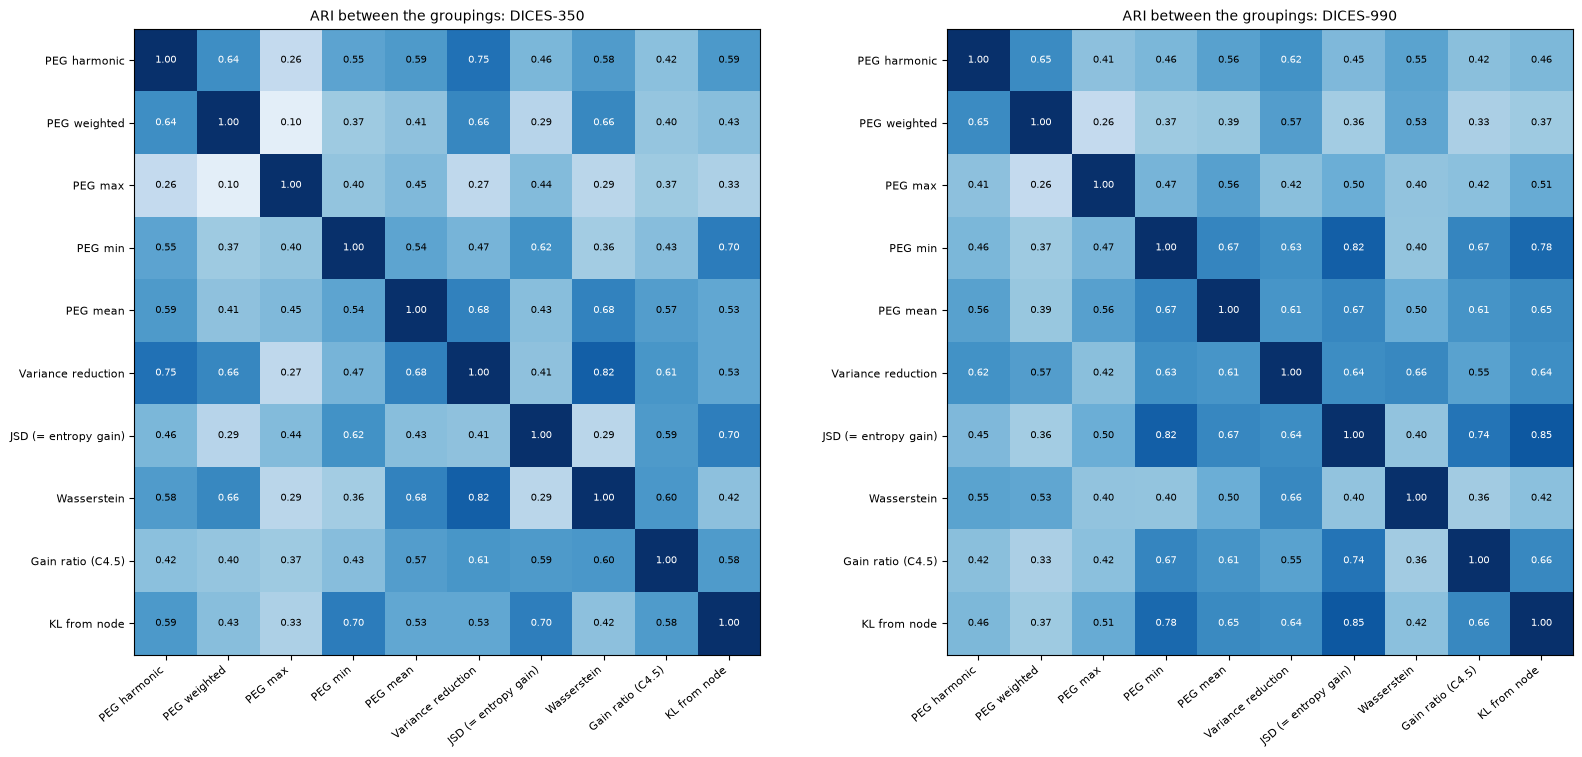

In [8]:
dices_agree = {}
if RUN_DICES:
    for name in dices:
        dices_agree[name] = agreement(dices_trees[name])           # the trees of section 3
        print(f"\n{name}: {len(dices[name]['retained'])} polarised items")
        for m in ("ARI", "first split", "node-level"):
            print(m); display(dices_agree[name][m].round(3))

panels = [(n, a["ARI"]) for n, a in dices_agree.items()]
if plt is not None:
    fig, axes = plt.subplots(1, len(panels), figsize=(8.2 * len(panels), 7.6), squeeze=False)
    for ax, (title, mat) in zip(axes[0], panels):
        heatmap(ax, mat, f"ARI between the groupings: {title}")
    plt.tight_layout(); plt.show()

## 5. Pairwise Wilcoxon signed-rank test on residual nDFU

For each DICES dataset separately. The unit is the **item**: for every retained item, each criterion's tree (built in section 3 at that
criterion's own tuned threshold, nothing is rebuilt here) leaves a residual nDFU, the annotator-weighted mean over its leaves, the same
quantity as in section 4. Every pair of criteria is then compared with a two-sided `scipy.stats.wilcoxon` signed-rank test on the
per-item differences (the items are the same for all criteria, so the comparison is paired).

- the p-value matrix is symmetric; when every difference of a pair is zero the p-value is set to 1.0;
- the effect-size matrix is the mean per-item difference **row minus column**, so a **positive** value means the row criterion leaves
  *more* polarization in its leaves than the column criterion;
- p-values are not corrected for the 45 comparisons per dataset (10 criteria);
- the trees of different criteria have different numbers of leaves at these settings and a bigger tree leaves less, so the mean leaves
  per tree is printed too: a difference may partly be a difference in tree size.

In [9]:
from scipy.stats import wilcoxon


def item_residuals(name):
    """per-item residual nDFU (annotator-weighted over the leaves of the item's tree), from the trees of section 3"""
    ids = dices[name]["retained"]
    out = {}
    for c in CRITERIA:
        tr = dices_trees[name][c]
        out[c] = [sum(n * nd for n, nd in tr[t]["leaves"]) / sum(n for n, _ in tr[t]["leaves"]) for t in ids]
    return pd.DataFrame(out, index=ids)


def wilcoxon_p(a, b):
    if np.all(a - b == 0):                      # every difference is zero: nothing to rank, no evidence of a difference
        return 1.0
    try:
        return float(wilcoxon(a, b, alternative="two-sided").pvalue)
    except ValueError:
        return 1.0


wilcoxon_results = {}
if RUN_DICES:
    names = list(CRITERIA)
    for name in dices:
        res = item_residuals(name)
        P = pd.DataFrame(1.0, index=names, columns=names)
        E = pd.DataFrame(0.0, index=names, columns=names)
        for a, b in itertools.permutations(names, 2):
            E.loc[a, b] = float((res[a] - res[b]).mean())
        for a, b in itertools.combinations(names, 2):
            P.loc[a, b] = P.loc[b, a] = wilcoxon_p(res[a].to_numpy(), res[b].to_numpy())
        wilcoxon_results[name] = (P, E)

        leaves = pd.Series({c: np.mean([len(dices_trees[name][c][t]["leaves"]) for t in dices[name]["retained"]]) for c in names})
        print("=" * 90)
        print(f"{name}: {len(res)} items, paired two-sided Wilcoxon signed-rank test on per-item residual nDFU")
        print("=" * 90)
        print("\nMean residual nDFU and mean leaves per tree (at each criterion's tuned threshold)")
        display(pd.DataFrame({"mean residual nDFU": res.mean(), "mean leaves per tree": leaves}).round(3))
        print("\np-values (two-sided Wilcoxon signed-rank, uncorrected)")
        display(P.round(4))
        print("\nEffect sizes: mean difference in residual nDFU, row minus column (positive = the row leaves MORE polarization than the column)")
        display(E.round(4))
else:
    print("DICES files not found: nothing to run.")

DICES-350: 28 items, paired two-sided Wilcoxon signed-rank test on per-item residual nDFU

Mean residual nDFU and mean leaves per tree (at each criterion's tuned threshold)


,mean residual nDFU,mean leaves per tree
PEG harmonic,0.444,7.536
PEG weighted,0.460,4.821
PEG max,0.499,10.429
PEG min,0.402,13.179
PEG mean,0.514,6.786
Variance reduction,0.484,4.857
JSD (= entropy gain),0.395,15.536
Wasserstein,0.527,3.321
Gain ratio (C4.5),0.449,10.250
KL from node,0.406,13.214



p-values (two-sided Wilcoxon signed-rank, uncorrected)


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.0000,0.2146,0.2692,0.0386,0.0089,0.0409,0.0214,0.0027,0.7089,0.0479
PEG weighted,0.2146,1.0000,0.6830,0.0074,0.2432,0.7299,0.0054,0.0281,0.3905,0.0117
PEG max,0.2692,0.6830,1.0000,0.0019,0.3011,0.7570,0.0014,0.0777,0.1985,0.0092
PEG min,0.0386,0.0074,0.0019,1.0000,0.0005,0.0012,0.4593,0.0003,0.2641,0.8484
PEG mean,0.0089,0.2432,0.3011,0.0005,1.0000,0.3003,0.0001,0.1961,0.0048,0.0006
Variance reduction,0.0409,0.7299,0.7570,0.0012,0.3003,1.0000,0.0004,0.0152,0.0229,0.0018
JSD (= entropy gain),0.0214,0.0054,0.0014,0.4593,0.0001,0.0004,1.0000,0.0001,0.1913,0.5111
Wasserstein,0.0027,0.0281,0.0777,0.0003,0.1961,0.0152,0.0001,1.0000,0.0022,0.0004
Gain ratio (C4.5),0.7089,0.3905,0.1985,0.2641,0.0048,0.0229,0.1913,0.0022,1.0000,0.5699
KL from node,0.0479,0.0117,0.0092,0.8484,0.0006,0.0018,0.5111,0.0004,0.5699,1.0000



Effect sizes: mean difference in residual nDFU, row minus column (positive = the row leaves MORE polarization than the column)


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,0.0000,-0.0163,-0.0545,0.0422,-0.0696,-0.0399,0.0494,-0.0829,-0.0053,0.0381
PEG weighted,0.0163,0.0000,-0.0382,0.0584,-0.0533,-0.0236,0.0656,-0.0666,0.0110,0.0544
PEG max,0.0545,0.0382,0.0000,0.0966,-0.0151,0.0146,0.1038,-0.0285,0.0492,0.0926
PEG min,-0.0422,-0.0584,-0.0966,0.0000,-0.1117,-0.0820,0.0072,-0.1251,-0.0475,-0.0040
PEG mean,0.0696,0.0533,0.0151,0.1117,0.0000,0.0297,0.1189,-0.0133,0.0643,0.1077
Variance reduction,0.0399,0.0236,-0.0146,0.0820,-0.0297,0.0000,0.0892,-0.0430,0.0346,0.0780
JSD (= entropy gain),-0.0494,-0.0656,-0.1038,-0.0072,-0.1189,-0.0892,0.0000,-0.1323,-0.0547,-0.0112
Wasserstein,0.0829,0.0666,0.0285,0.1251,0.0133,0.0430,0.1323,0.0000,0.0776,0.1210
Gain ratio (C4.5),0.0053,-0.0110,-0.0492,0.0475,-0.0643,-0.0346,0.0547,-0.0776,0.0000,0.0434
KL from node,-0.0381,-0.0544,-0.0926,0.0040,-0.1077,-0.0780,0.0112,-0.1210,-0.0434,0.0000


... (2 outputs left out)


p-values (two-sided Wilcoxon signed-rank, uncorrected)


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,1.0000,0.0286,0.0413,0.0000,0.2575,0.0038,0.0000,0.0520,0.0032,0.0000
PEG weighted,0.0286,1.0000,0.0089,0.0001,0.5682,0.1640,0.0004,0.0007,0.2178,0.0001
PEG max,0.0413,0.0089,1.0000,0.0000,0.0017,0.0000,0.0000,0.9759,0.0000,0.0000
PEG min,0.0000,0.0001,0.0000,1.0000,0.0000,0.0001,0.1774,0.0000,0.0007,0.8689
PEG mean,0.2575,0.5682,0.0017,0.0000,1.0000,0.0122,0.0000,0.0035,0.0183,0.0000
Variance reduction,0.0038,0.1640,0.0000,0.0001,0.0122,1.0000,0.0117,0.0000,0.9304,0.0078
JSD (= entropy gain),0.0000,0.0004,0.0000,0.1774,0.0000,0.0117,1.0000,0.0000,0.0024,0.3368
Wasserstein,0.0520,0.0007,0.9759,0.0000,0.0035,0.0000,0.0000,1.0000,0.0000,0.0000
Gain ratio (C4.5),0.0032,0.2178,0.0000,0.0007,0.0183,0.9304,0.0024,0.0000,1.0000,0.0003
KL from node,0.0000,0.0001,0.0000,0.8689,0.0000,0.0078,0.3368,0.0000,0.0003,1.0000



Effect sizes: mean difference in residual nDFU, row minus column (positive = the row leaves MORE polarization than the column)


,PEG harmonic,PEG weighted,PEG max,PEG min,PEG mean,Variance reduction,JSD (= entropy gain),Wasserstein,Gain ratio (C4.5),KL from node
PEG harmonic,0.0000,0.0192,-0.0332,0.0598,0.0105,0.0330,0.0574,-0.0214,0.0356,0.0633
PEG weighted,-0.0192,0.0000,-0.0524,0.0406,-0.0087,0.0137,0.0382,-0.0406,0.0164,0.0441
PEG max,0.0332,0.0524,0.0000,0.0930,0.0437,0.0662,0.0906,0.0118,0.0688,0.0965
PEG min,-0.0598,-0.0406,-0.0930,0.0000,-0.0493,-0.0269,-0.0024,-0.0812,-0.0242,0.0035
PEG mean,-0.0105,0.0087,-0.0437,0.0493,0.0000,0.0224,0.0469,-0.0319,0.0251,0.0528
Variance reduction,-0.0330,-0.0137,-0.0662,0.0269,-0.0224,0.0000,0.0244,-0.0543,0.0027,0.0304
JSD (= entropy gain),-0.0574,-0.0382,-0.0906,0.0024,-0.0469,-0.0244,0.0000,-0.0788,-0.0218,0.0059
Wasserstein,0.0214,0.0406,-0.0118,0.0812,0.0319,0.0543,0.0788,0.0000,0.0570,0.0847
Gain ratio (C4.5),-0.0356,-0.0164,-0.0688,0.0242,-0.0251,-0.0027,0.0218,-0.0570,0.0000,0.0277
KL from node,-0.0633,-0.0441,-0.0965,-0.0035,-0.0528,-0.0304,-0.0059,-0.0847,-0.0277,0.0000


## 6. Explanation efficiency

How much polarization a criterion explains **per split**, on the DICES items. For each criterion and each polarised item, from the trees
built in section 3 (nothing is rebuilt):

1. **initial** polarization: nDFU of all the annotators at the root;
2. **residual** polarization: annotator-weighted mean nDFU over the leaves (the quantity of section 4);
3. **explained** = initial - residual;
4. **splits** = number of internal nodes of the tree (a multiway split counts once);
5. **efficiency** = explained / splits, and 0 when the tree never splits or when explained <= 0 .

Efficiency is averaged over all polarised items of a dataset; "both" is the mean of the two datasets. Explained can be slightly negative
for an item, when annotators without a value on the splitting dimension drop out of the leaves; these items are kept as they are.

In [10]:
def item_efficiency(name, c):
    """per-item initial, residual, explained, splits and efficiency of criterion c, from the trees of section 4"""
    rows = []
    for t in dices[name]["retained"]:
        tr = dices_trees[name][c][t]
        y = dices[name]["items"][t]["y"]
        initial = float(ndfu_c(np.bincount(y - 1, minlength=D_SCALE)))
        residual = sum(n * nd for n, nd in tr["leaves"]) / sum(n for n, _ in tr["leaves"])
        splits = sum(v is not None for v in tr["decisions"].values())
        explained = initial - residual
        eff = 0.0 if (splits == 0 or explained <= 0) else explained / splits
        rows.append(dict(item=t, initial=initial, residual=residual, explained=explained, splits=splits, efficiency=eff))
    return pd.DataFrame(rows).set_index("item")


efficiency_items, efficiency_table = {}, {}
if RUN_DICES:
    for name in dices:
        efficiency_items[name] = {c: item_efficiency(name, c) for c in CRITERIA}
        efficiency_table[name] = pd.DataFrame({
            c: dict(efficiency=df["efficiency"].mean(), explained=df["explained"].mean(), splits=df["splits"].mean(),
                    initial=df["initial"].mean(), residual=df["residual"].mean(),
                    no_split_items=int((df["splits"] == 0).sum()), negative_explained_items=int((df["explained"] < 0).sum()))
            for c, df in efficiency_items[name].items()}).T
        print(f"{name}: {len(dices[name]['retained'])} polarised items, each criterion at its tuned threshold")
        display(efficiency_table[name].sort_values("efficiency", ascending=False).round(4))

    summary = pd.DataFrame({
        **{f"{n}: efficiency": t["efficiency"] for n, t in efficiency_table.items()},
        "both: efficiency": pd.concat([t["efficiency"] for t in efficiency_table.values()], axis=1).mean(axis=1),
        "both: explained": pd.concat([t["explained"] for t in efficiency_table.values()], axis=1).mean(axis=1),
        "both: splits": pd.concat([t["splits"] for t in efficiency_table.values()], axis=1).mean(axis=1)})
    summary = summary.sort_values("both: efficiency", ascending=False)
    summary.insert(0, "rank", range(1, len(summary) + 1))
    print("\nExplanation efficiency (polarization explained per split, higher is better), ranked by the mean of the two datasets")
    display(summary.round(4))
else:
    print("DICES files not found: nothing to run.")

DICES-350: 28 polarised items, each criterion at its tuned threshold


,efficiency,explained,splits,initial,residual,no_split_items,negative_explained_items
PEG weighted,0.0282,0.1217,2.4643,0.5821,0.4603,18.0,1.0
PEG harmonic,0.0192,0.1380,4.2857,0.5821,0.4441,12.0,1.0
PEG min,0.0179,0.1802,8.3214,0.5821,0.4019,6.0,2.0
JSD (= entropy gain),0.0171,0.1874,9.7857,0.5821,0.3947,4.0,2.0
KL from node,0.0165,0.1761,8.0000,0.5821,0.4059,8.0,2.0
Variance reduction,0.0163,0.0981,2.5357,0.5821,0.4839,18.0,1.0
Gain ratio (C4.5),0.0124,0.1327,6.0000,0.5821,0.4494,12.0,2.0
PEG max,0.0117,0.0835,5.9286,0.5821,0.4985,7.0,6.0
PEG mean,0.0095,0.0684,3.6786,0.5821,0.5136,15.0,3.0
Wasserstein,0.0089,0.0551,1.6071,0.5821,0.5270,22.0,2.0


DICES-990: 105 polarised items, each criterion at its tuned threshold


,efficiency,explained,splits,initial,residual,no_split_items,negative_explained_items
PEG min,0.0299,0.1388,5.0571,0.4853,0.3465,2.0,16.0
PEG weighted,0.0293,0.0982,1.9333,0.4853,0.3872,51.0,16.0
Variance reduction,0.0289,0.1119,3.6762,0.4853,0.3734,21.0,20.0
PEG harmonic,0.0286,0.0789,2.4952,0.4853,0.4064,36.0,24.0
KL from node,0.0285,0.1423,5.5238,0.4853,0.3431,1.0,18.0
JSD (= entropy gain),0.0277,0.1363,5.5429,0.4853,0.3490,0.0,18.0
Gain ratio (C4.5),0.0260,0.1146,5.0476,0.4853,0.3708,3.0,26.0
PEG mean,0.0232,0.0895,4.1429,0.4853,0.3958,14.0,27.0
Wasserstein,0.0203,0.0576,2.3048,0.4853,0.4277,45.0,27.0
PEG max,0.0151,0.0458,3.9048,0.4853,0.4396,16.0,40.0



Explanation efficiency (polarization explained per split, higher is better), ranked by the mean of the two datasets


,rank,DICES-350: efficiency,DICES-990: efficiency,both: efficiency,both: explained,both: splits
PEG weighted,1,0.0282,0.0293,0.0288,0.1099,2.1988
PEG harmonic,2,0.0192,0.0286,0.0239,0.1085,3.3905
PEG min,3,0.0179,0.0299,0.0239,0.1595,6.6893
Variance reduction,4,0.0163,0.0289,0.0226,0.1050,3.1060
KL from node,5,0.0165,0.0285,0.0225,0.1592,6.7619
JSD (= entropy gain),6,0.0171,0.0277,0.0224,0.1619,7.6643
Gain ratio (C4.5),7,0.0124,0.0260,0.0192,0.1236,5.5238
PEG mean,8,0.0095,0.0232,0.0164,0.0790,3.9107
Wasserstein,9,0.0089,0.0203,0.0146,0.0563,1.9560
PEG max,10,0.0117,0.0151,0.0134,0.0646,4.9167


## 7. Save the results

Three CSV files, written to `results/` next to this notebook (the numbers of the tables above, nothing recomputed):

- `dices_results.csv`: one row per criterion and dataset (DICES-350, DICES-990 and the mean of the two): the fixed threshold, the number
  of polarised items, leaves per tree, residual nDFU (unweighted and annotator-weighted) and the rank by the weighted residual.
- `dices_efficiency.csv`: the same rows with the explanation efficiency of section 6: initial and residual nDFU, explained, splits per
  tree, efficiency, the number of items where the tree never splits and the rank by efficiency.
- `ari_results.csv`: the agreement between the trees of every pair of criteria, in long form (`dataset`, `measure`, `criterion_row`,
  `criterion_col`, `value`): the ARI of the groupings of the annotators, plus the first-split, node-level and dimension-set agreement.

In [11]:
OUT = Path.cwd() / "results"
OUT.mkdir(exist_ok=True)
form = lambda c: "relative" if best[c]["relative"] else "absolute"
BOTH = "both (mean of the two datasets)"

# ---- 1. residual nDFU at each criterion's fixed threshold
rows = []
for name, t in dices_table.items():
    rank = t["residual_nDFU_weighted"].rank(method="min").astype(int)
    for c in CRITERIA:
        rows.append(dict(criterion=c, threshold_form=form(c), threshold=best[c]["h"], dataset=name,
                         n_items=len(dices[name]["retained"]), leaves_per_tree=float(t.loc[c, "leaves_per_tree"]),
                         residual_nDFU_unweighted=float(t.loc[c, "residual_nDFU_unweighted"]),
                         residual_nDFU_weighted=float(t.loc[c, "residual_nDFU_weighted"]), rank_by_weighted_residual=int(rank[c])))
both_w = pd.Series({c: np.mean([dices_table[n].loc[c, "residual_nDFU_weighted"] for n in dices_table]) for c in CRITERIA})
both_rank = both_w.rank(method="min").astype(int)
for c in CRITERIA:
    rows.append(dict(criterion=c, threshold_form=form(c), threshold=best[c]["h"], dataset=BOTH,
                     n_items=sum(len(dices[n]["retained"]) for n in dices_table),
                     leaves_per_tree=float(np.mean([dices_table[n].loc[c, "leaves_per_tree"] for n in dices_table])),
                     residual_nDFU_unweighted=float(np.mean([dices_table[n].loc[c, "residual_nDFU_unweighted"] for n in dices_table])),
                     residual_nDFU_weighted=float(both_w[c]), rank_by_weighted_residual=int(both_rank[c])))
dices_csv = pd.DataFrame(rows)
dices_csv.to_csv(OUT / "dices_results.csv", index=False)
print("dices_results.csv:", dices_csv.shape)

# ---- 2. explanation efficiency
rows = []
eff_both = pd.concat([t["efficiency"] for t in efficiency_table.values()], axis=1).mean(axis=1)
eff_rank_both = eff_both.rank(method="min", ascending=False).astype(int)
for name, t in efficiency_table.items():
    rank = t["efficiency"].rank(method="min", ascending=False).astype(int)
    for c in CRITERIA:
        rows.append(dict(criterion=c, dataset=name, n_items=len(dices[name]["retained"]),
                         initial_nDFU=float(t.loc[c, "initial"]), residual_nDFU=float(t.loc[c, "residual"]),
                         explained=float(t.loc[c, "explained"]), splits_per_tree=float(t.loc[c, "splits"]),
                         efficiency=float(t.loc[c, "efficiency"]), no_split_items=int(t.loc[c, "no_split_items"]),
                         negative_explained_items=int(t.loc[c, "negative_explained_items"]), rank_by_efficiency=int(rank[c])))
for c in CRITERIA:
    pick = lambda col: float(np.mean([t.loc[c, col] for t in efficiency_table.values()]))
    rows.append(dict(criterion=c, dataset=BOTH, n_items=sum(len(dices[n]["retained"]) for n in dices_table),
                     initial_nDFU=pick("initial"), residual_nDFU=pick("residual"), explained=pick("explained"),
                     splits_per_tree=pick("splits"), efficiency=float(eff_both[c]),
                     no_split_items=int(sum(t.loc[c, "no_split_items"] for t in efficiency_table.values())),
                     negative_explained_items=int(sum(t.loc[c, "negative_explained_items"] for t in efficiency_table.values())),
                     rank_by_efficiency=int(eff_rank_both[c])))
eff_csv = pd.DataFrame(rows)
eff_csv.to_csv(OUT / "dices_efficiency.csv", index=False)
print("dices_efficiency.csv:", eff_csv.shape)

# ---- 3. agreement between the trees
MEASURE_NAME = {"ARI": "ARI", "first split": "first_split_agreement", "node-level": "node_level_agreement",
                "dimension sets (Jaccard)": "dimension_set_jaccard"}
rows = []
for name, ag in dices_agree.items():
    for measure, mat in ag.items():
        for a in mat.index:
            for b in mat.columns:
                rows.append(dict(dataset=name, n_texts=len(dices[name]["retained"]), measure=MEASURE_NAME[measure],
                                 criterion_row=a, criterion_col=b, value=float(mat.loc[a, b])))
ari_csv = pd.DataFrame(rows)
ari_csv.to_csv(OUT / "ari_results.csv", index=False)
print("ari_results.csv:", ari_csv.shape)
print("saved in", OUT)

dices_results.csv: (30, 9)
dices_efficiency.csv: (30, 11)
ari_results.csv: (800, 6)
saved in C:\Users\Sokratis\OneDrive\Υπολογιστής\ερευνα\HumanModelAlign\polarizedtrees\criteria_comparison\results
